# MNIST CNN 첫 실습

목표: MNIST 이미지 확인 → CNN 모델 만들기 → 학습하기 → 정확도 확인 → 에포크 변경 실험

> 이 파일은 <수행평가 전 연습용>입니다. 처음부터 모든 코드를 외우는 것이 아니라, 각 단계의 [역할]을 이해하는 것이 목표입니다.

학번/이름: 1315 정서진

## ① 도구 불러오기
- **TensorFlow/Keras**: CNN을 만드는 데 사용하는 딥러닝 도구
- **Matplotlib**: 이미지를 화면에 보여 주는 도구

아래 셀을 실행하기

In [11]:
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

## ② MNIST 데이터셋 불러오기
- **MNIST**: 0~9까지 손글씨 숫자 이미지와 정답을 모아 둔 데이터셋
- **x**: 이미지, **y**: 이미지의 정답
- **train**: 학습용, **test**: 학습 후 확인용

In [12]:
# MNIST 데이터셋을 불러와 학습용(train)과 테스트용(test)으로 나누어 저장
# 원본 MNIST는 학습용 60,000장, 테스트용 10,000장

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("학습용 이미지:", x_train.shape)
print("테스트용 이미지:", x_test.shape)

학습용 이미지: (60000, 28, 28)
테스트용 이미지: (10000, 28, 28)


## ③ 숫자 이미지 확인하기

첫 번째 손글씨 이미지와 정답을 확인
CNN을 학습시키는 단계가 아니라 학습에 사용할 데이터를 살펴보는 단계

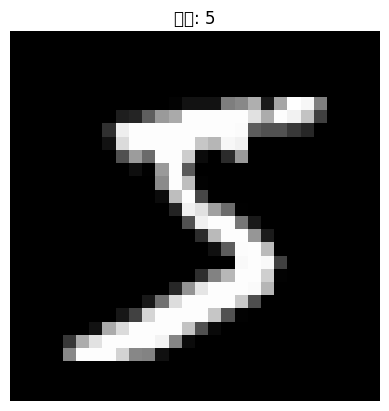

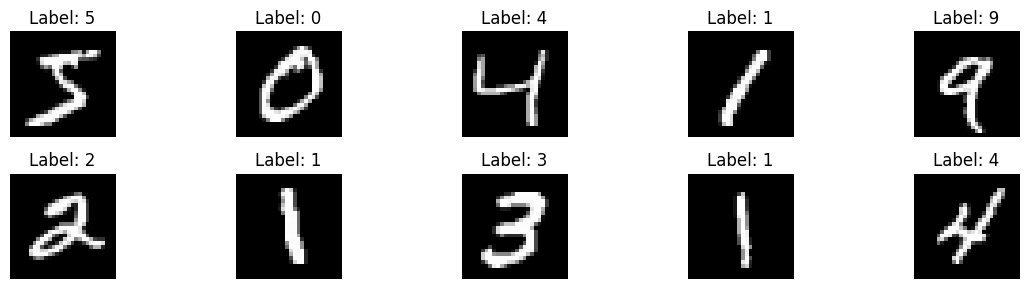

In [13]:
# 학습용 첫 번째 숫자 이미지(x_train[0])를 화면에 표시
# cmap="gray": 흑백(회색조)으로 표시

plt.imshow(x_train[0], cmap="gray")
plt.title(f"정답: {y_train[0]}")
plt.axis("off")
plt.show()

plt.figure(figsize=(12, 3))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()

## ④ 학습 데이터 준비하기

- 실습 시간을 줄이기 위해 학습용 12,000장, 테스트용 2,000장만 사용
- 정규화: 픽셀 값 0~255를 0~1로 바꾸기 (`/ 255.0`)
- `[..., None]`은 CNN에서 사용할 흑백 채널 1개를 추가
- 이 셀은 반복 실행하지 않도록 합니다.

In [14]:

# 정규화 전
print("정규화 전 최댓값:", x_train.max())
print("정규화 전 최솟값:", x_train.min())

# 정규화
x_train = x_train[:12000] / 255.0
y_train = y_train[:12000]
x_test = x_test[:2000] / 255.0
y_test = y_test[:2000]

# 정규화 후
print("정규화 후 최댓값:", x_train.max())
print("정규화 후 최솟값:", x_train.min())

# CNN 입력을 위한 채널 추가
x_train = x_train[..., None]
x_test = x_test[..., None]

정규화 전 최댓값: 255
정규화 전 최솟값: 0
정규화 후 최댓값: 1.0
정규화 후 최솟값: 0.0


## ⑤ CNN 모델 만들기



| 코드 | 역할 |
|---|---|
| `Conv2D` | 숫자 이미지에서 특징 찾기 |
| `MaxPooling2D` | 특징 정보를 요약하기 |
| `Flatten` | 데이터를 한 줄로 펼치기 |
| `Dense(64)` | 64개의 뉴런으로 은닉층을 만들어 이미지의 특징을 조합하고 학습하기 |
| `Dense(10)` | 숫자 0~9, 10개 중 하나를 예측하도록 출력하기 |

> *중요:* 에포크 수를 바꾸어 다시 실험할 때는 ⑤ 모델 만들기 셀부터 다시 실행해야 새 모델이 만들어짐

In [15]:
# 난수 시드 고정: 실험할 때 동일한 초기 조건 사용
keras.utils.set_random_seed(42)

# Sequential: 신경망의 층을 입력부터 출력까지 순서대로 쌓아 모델 만들기
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),  # ★ 추가
    layers.Dense(10, activation="softmax")
])

# compile: 모델을 학습시키기 전에 학습 방법과 평가 기준 설정
model.compile(
    optimizer="adam",

    # 정답이 0~9처럼 정수일 때 사용하는 분류용 손실함수
    loss="sparse_categorical_crossentropy",

    # accuracy: 정답을 맞힌 비율(정확도)을 확인
    metrics=["accuracy"]
)

Q: optimizer="adam" 설명하기


## ⑥ CNN 학습하기

`epochs=5`은 학습 데이터를 전체적으로 5번 반복해서 학습한다는 의미

학습을 실행하고 마지막에 표시되는 `accuracy`와 `loss` 살펴보기

In [16]:
# fit: 학습용 이미지(x_train)와 정답(y_train)으로 CNN 모델 학습

model.fit(x_train, y_train, epochs=5, batch_size=32, validation_split=0.2 )

Epoch 1/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8692 - loss: 0.4783 - val_accuracy: 0.9379 - val_loss: 0.2119
Epoch 2/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9451 - loss: 0.1881 - val_accuracy: 0.9513 - val_loss: 0.1552
Epoch 3/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9661 - loss: 0.1201 - val_accuracy: 0.9621 - val_loss: 0.1248
Epoch 4/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9767 - loss: 0.0833 - val_accuracy: 0.9629 - val_loss: 0.1089
Epoch 5/5
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9853 - loss: 0.0586 - val_accuracy: 0.9663 - val_loss: 0.1000


**결과 해석**
(1회차와 5회차 정확도 비교, 학습횟수 증가에 따른 손실값 변화추이, 정확도와 손실값의 변화를 바탕으로 CNN모델의 학습 결과 설명하기)
:CNN 모델을 5번 반복 학습한 결과, 정확도는 ______%에서 ______%로 증가하였고 손실값은 ______에서 ______로 감소하였다. 이를 통해 학습이 진행되면서 모델이 손글씨 숫자의 특징을 더 잘 학습하였음을 알 수 있다.

validation_split=0.2 : 검증데이터
: 12,000장 중 9,600장은 실제 학습에 사용, 2,400장은 검증에 사용

## ⑦ 정확도 확인하기

학습에 사용하지 않은 테스트 이미지로 모델의 정확도를 확인

- `accuracy`: 정답을 맞힌 비율 (높을수록 좋음)
- `loss`: 예측과 정답의 차이를 나타내는 손실값 (일반적으로 낮을수록 좋음)

In [17]:
loss, accuracy = model.evaluate(x_test, y_test)
# 테스트 정확도, 손실값 확인

print("테스트 정확도:", round(accuracy * 100, 2), "%")
print("테스트 손실값:", round(loss, 4))

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9495 - loss: 0.1594
테스트 정확도: 94.95 %
테스트 손실값: 0.1594


## ⑧ 조건 한 가지만 변경하기

1. 첫 번째 실험(`epochs=5`)의 테스트 정확도 기록하기
2. **⑤ CNN 모델 만들기 셀을 다시 실행**해 모델을 새로 만들기
3. **⑥ 학습하기 셀**에서 `epochs=5`을 `epochs=8`로 변경하고 실행
4. **⑦ 정확도 확인하기 셀**을 실행하여 결과를 기록

| 구분 | 학습 횟수 | 테스트 정확도 |
|---|---:|---|
| 실험 1 | 5 | __________ |
| 실험 2 | 8 | __________ |

**확인 문제**

1. `epochs`를 5에서 8로 바꾸었을 때 결과가 어떻게 변했나요?
2. 정확도가 달라진 이유를 자신의 생각으로 한 문장으로 적어 보세요.


## ⑨ 기준·A·B 3개 모델 비교 실험

실제 Fashion-MNIST 평가와 같은 방법으로 **독립적인 3개 모델**을 만듭니다.

| 모델 | Epoch | Dense 뉴런 수 | 비교할 내용 |
|---|---:|---:|---|
| 기준 | 5 | 64 | 기준 조건 |
| A | 10 | 64 | Epoch만 변경 |
| B | 5 | 128 | Dense 뉴런 수만 변경 |

- **기준 ↔ A**, **기준 ↔ B**를 각각 비교합니다.
- 세 모델은 같은 데이터로 학습하며, 매번 **새 모델**을 만듭니다.
- **⑤~⑧의 기존 모델 결과와 섞지 않고** 아래 ⑨ 결과끼리만 비교합니다.


In [18]:
# 【추가】 세 모델을 한 번에 학습하고 훈련·검증 결과 확인
plans = [("기준", 5, 64), ("A", 10, 64), ("B", 5, 128)]
models = {}

for name, epochs, units in plans:
    keras.utils.set_random_seed(42)
    m = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(16, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(units, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = m.fit(x_train, y_train, epochs=epochs, batch_size=32,
              validation_split=0.2, verbose=0)
    models[name] = m
    print(f"{name} (Epoch={epochs}, Dense={units})")
    print(f"  훈련: 정확도 {h.history['accuracy'][-1]*100:.2f}%, 손실 {h.history['loss'][-1]:.4f}")
    print(f"  검증: 정확도 {h.history['val_accuracy'][-1]*100:.2f}%, 손실 {h.history['val_loss'][-1]:.4f}")


기준 (Epoch=5, Dense=64)
  훈련: 정확도 98.53%, 손실 0.0586
  검증: 정확도 96.63%, 손실 0.1000
A (Epoch=10, Dense=64)
  훈련: 정확도 99.80%, 손실 0.0117
  검증: 정확도 96.58%, 손실 0.1194
B (Epoch=5, Dense=128)
  훈련: 정확도 98.95%, 손실 0.0416
  검증: 정확도 97.08%, 손실 0.0894


## ⑩ 선택한 모델의 테스트 정확도·손실값 확인

⑨에서 출력한 **검증 정확도와 검증 손실값**을 비교해 기준/A/B 중 하나를 고르세요. 모델을 선택한 **다음에** 테스트 데이터로 최종 확인합니다.


In [19]:
# 검증 결과를 보고 선택한 이름으로 바꾸기: "기준", "A", "B"
choice = "B"
loss, accuracy = models[choice].evaluate(x_test, y_test, verbose=0)
print(f"{choice} 모델의 테스트 정확도: {accuracy*100:.2f}%")
print(f"{choice} 모델의 테스트 손실값: {loss:.4f}")


B 모델의 테스트 정확도: 95.65%
B 모델의 테스트 손실값: 0.1362
